In [1]:

#! Download Zip into same directory as Notebook
# Unzip file
!mkdir -p dogscats/subset
!unzip -o -q dogs-vs-cats-subset.zip -d dogscats

In [2]:
import torch
import torch.nn as nn
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision import transforms
import os
import numpy as np
from captum.attr import visualization as viz
from captum.attr import IntegratedGradients, LayerGradCam, LayerAttribution
from tqdm import tqdm

In [3]:
# Data prep
base_dir = 'dogscats/subset'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

#Defining Data augmentation for Training
train_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomRotation(40),
    transforms.RandomResizedCrop(150, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, shear=0.2, scale=(0.8, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

data_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(root=val_dir, transform=data_transform)
test_dataset = datasets.ImageFolder(root=test_dir, transform=data_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=8)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=8)

In [4]:
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()
        self.pool = nn.MaxPool2d(2, 2)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(128 * 9 * 9, 512)  # 9x9 is the size after max pooling
        self.dropout = nn.Dropout(0.5)  # Adding dropout
        self.fc2 = nn.Linear(512, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = self.pool(torch.relu(self.conv4(x)))
        x = self.flatten(x)
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.sigmoid(self.fc2(x))
        return x

def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs=100, device='cuda'):
    best_val_loss = float('inf')
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        train_bar = tqdm(train_loader, desc=f'[Train] Epoch {epoch+1}/{num_epochs}')
        for images, labels in train_bar:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            train_bar.set_postfix({'loss': loss.item()})

        avg_train_loss = running_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        model.eval()
        val_loss = 0.0
        val_preds = []
        val_true = []
        with torch.no_grad():
            val_bar = tqdm(val_loader, desc=f'[Test]  Epoch {epoch+1}/{num_epochs}')
            for val_images, val_labels in val_bar:
                val_images = val_images.to(device)
                val_labels = val_labels.float().unsqueeze(1).to(device)

                val_outputs = model(val_images)
                batch_loss = criterion(val_outputs, val_labels)
                val_loss += batch_loss.item()

                val_preds.extend((val_outputs > 0.5).cpu().numpy())
                val_true.extend(val_labels.cpu().numpy())

                val_bar.set_postfix({'loss': batch_loss.item()})

        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        val_preds = np.array(val_preds)
        val_true = np.array(val_true)
        val_acc = (val_preds == val_true).mean()

        print(f'Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}')

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'train_losses': train_losses,
                'val_losses': val_losses,
                'best_val_loss': best_val_loss,
            }, 'best_model.pth')

    checkpoint = torch.load('best_model.pth')
    model.load_state_dict(checkpoint['model_state_dict'])
    return model, train_losses, val_losses

def evaluate_model(model, test_loader, device='cuda'):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        test_bar = tqdm(test_loader, desc='Testing')
        for test_images, test_labels in test_bar:
            test_images = test_images.to(device)
            test_labels = test_labels.to(device)

            outputs = model(test_images)
            predicted = (outputs > 0.5).float()

            total += test_labels.size(0)
            correct += (predicted.squeeze() == test_labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(test_labels.cpu().numpy())

            test_acc = correct / total
            test_bar.set_postfix({'acc': test_acc})

    test_acc = correct / total
    print(f'\nTest accuracy: {test_acc:.4f}')

    return test_acc, all_preds, all_labels


model = ConvNet()
criterion = nn.BCELoss()
optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-4)


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

if(os.path.exists("best_model.pth")):
    checkpoint = torch.load('best_model.pth')
    model.load_state_dict(checkpoint['model_state_dict'])
else:
# Train the model
    model, train_losses, val_losses = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        num_epochs=150,
        device=device
    )
print(model)

# Evaluate the model
test_acc, test_preds, test_labels = evaluate_model(
    model=model,
    test_loader=test_loader,
    device=device
)


/tmp/ipykernel_30926/712796692.py:136: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('best_model.pth')


ConvNet(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=10368, out_features=512, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


Testing: 100%|██████████| 32/32 [00:01<00:00, 22.97it/s, acc=0.813]


Test accuracy: 0.8130


### Explainer Methods
In this section, two model interpretability techniques are used to understand how our trained model makes decisions for classifying images as either cats or dogs. The two methods that are covered are:

- Integrated Gradients: A method that attributes the prediction of a neural network to its input features by approximating the integral of gradients between the input and a baseline.
- Grad-CAM: A visual explanation method that uses the gradients of the target class flowing into the final convolutional layer to create a heatmap that highlights important regions in the input image for making predictions.

### Integrated Gradients
Integrated Gradients work by comparing the gradients of the model's predictions with respect to the input features, starting from a baseline (which is usually a black image) and gradually moving towards the actual input. The integrated gradient is the average of the gradients taken along this path. The method satisfies two important properties: 
- sensitivity (capturing all feature contributions)
- implementation invariance (consistent across equivalent models).

The integral can be approximated using a Riemann Sum or Gauss Legendre quadrature rule.

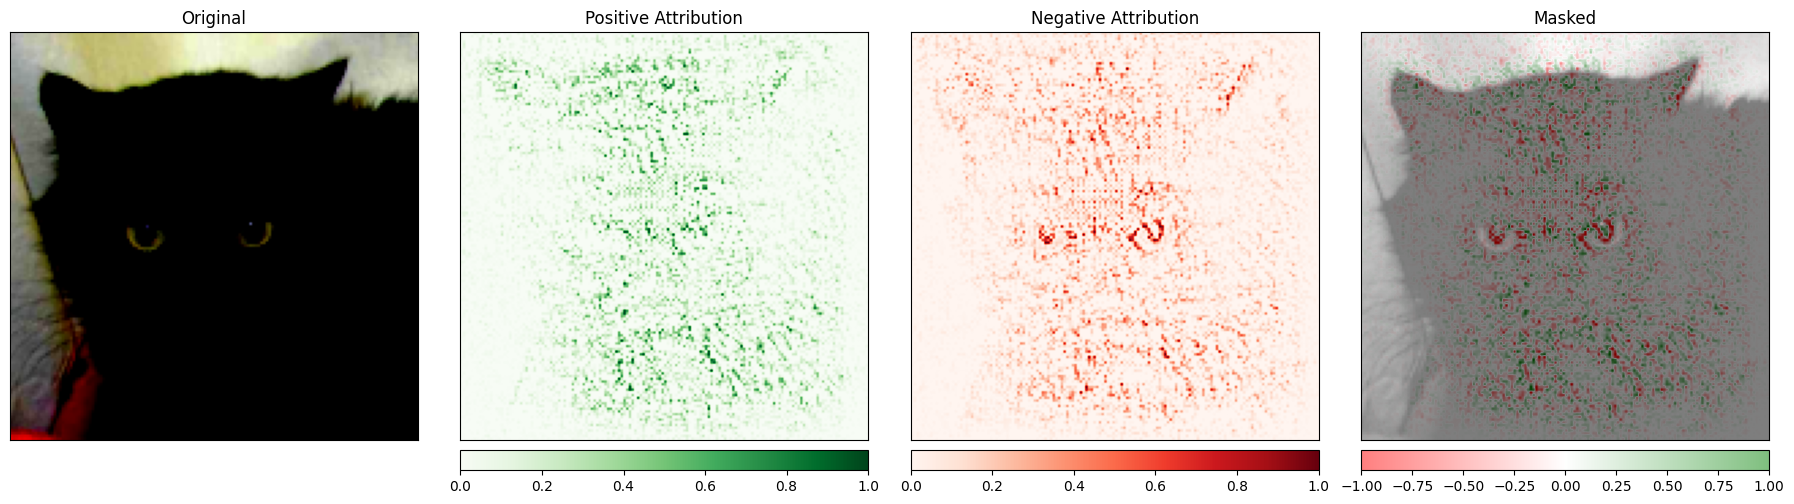

In [5]:
data_iter = iter(test_loader)
images, labels = next(data_iter)

input1 = images[0]
label1 = labels[0]

input1.requires_grad = True

baseline1 = torch.zeros_like(input1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input1 = input1.to(device)
label1 = label1.to(device)
baseline1 = baseline1.to(device)

ig = IntegratedGradients(model)

attribution, approximation_error = ig.attribute(
    (input1.unsqueeze(0)),
    baselines=(baseline1.unsqueeze(0)),
    method='gausslegendre',
    target=label1,
    return_convergence_delta=True,
    n_steps=200
)

_ = viz.visualize_image_attr_multiple(np.transpose(attribution.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      np.transpose(input1.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      ["original_image", "heat_map", "heat_map","blended_heat_map"],
                                      ["all", "positive", "negative", "all"],
                                      show_colorbar=True,
                                      titles=["Original", "Positive Attribution", "Negative Attribution", "Masked"],
                                      fig_size=(18, 6)
                                     )


The green areas highlight the parts of the image that contributed positively to the model's decision. In other words, these regions (shown in darker green) had a positive influence on the model classifying the image as the predicted class. The more intense the green color, the stronger the positive contribution.

The red areas indicate the parts of the image that had a negative influence on the model's prediction. These regions made the model less confident about its prediction for the selected class. Darker red indicates a stronger negative impact.

#### Grad-Cam
Grad-CAM (Gradient-weighted Class Activation Mapping) is a method used to understand which parts of an image a CNN focuses on when making predictions. It works by:

- Computing gradients of the target class with respect to the activations of the last convolutional layer.
- Averaging these gradients over the width and height of each channel (feature map).
- Multiplying the averaged gradients by the activations and summing over all channels (Weighted Sum).
- Applying ReLU to keep only positive attributions, highlighting important regions.
- Finally, the resulting 2D heatmap is upsampled to the size of the input image and overlaid to show where the model focused.

This method reveals the regions in an image most relevant for the model's decision, helping to visualize what drives the classification.

However, in this case, I decided to highlight the progression of abstraction across the network layers.
Therefore, all layers are shown in order below, visualizing how each contributes to the model's decision-making process.

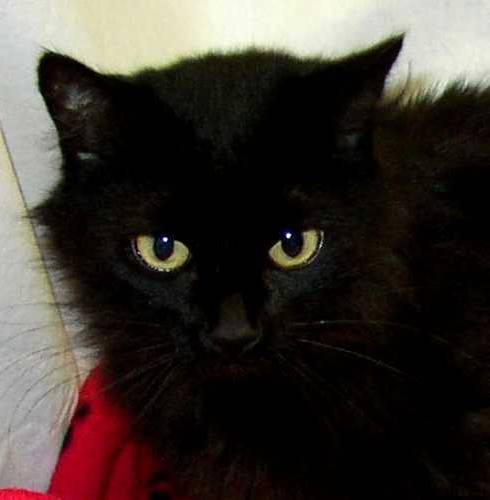

/workspaces/eng-ai-agents/.venv/lib/python3.11/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


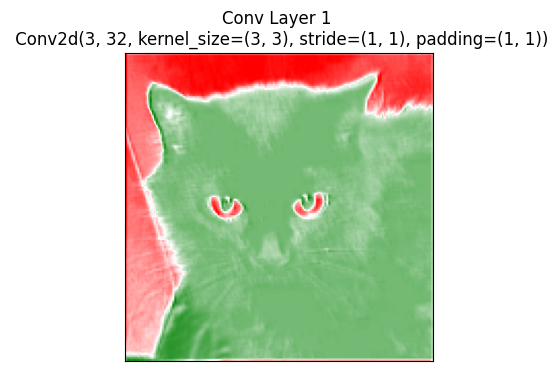

/workspaces/eng-ai-agents/.venv/lib/python3.11/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


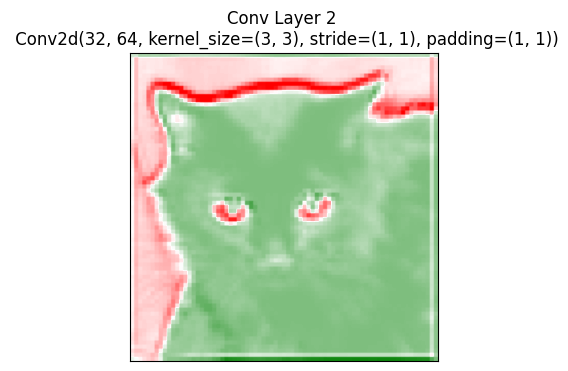

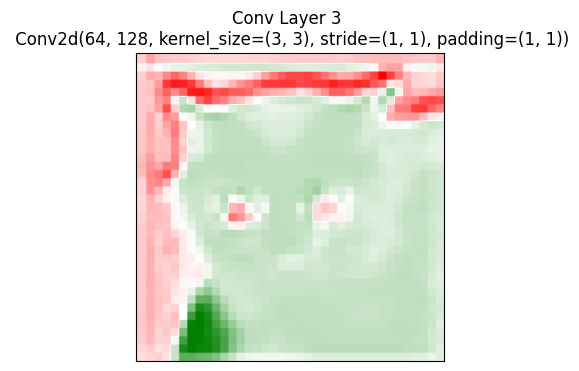

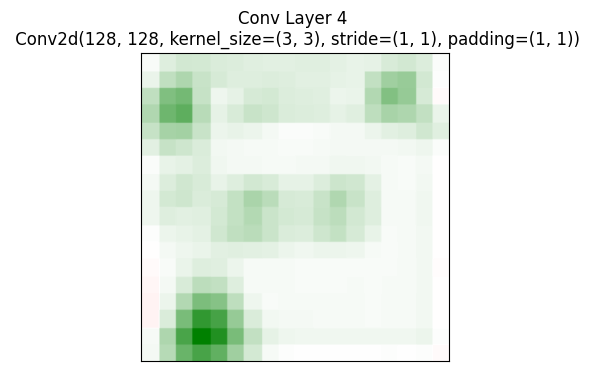

In [6]:
from PIL import Image

layers = [model.conv1, model.conv2, model.conv3, model.conv4]
img_path = "dogscats/subset/test/cats/cat.1500.jpg"
original_image = Image.open(img_path)
Image._show(original_image)
input_tensor = data_transform(original_image).unsqueeze(0)
input_tensor.to(device)

if torch.cuda.is_available():
    input_tensor = input_tensor.cuda()

attributions = []
for i, target_layer in enumerate(layers):

    grad_cam = LayerGradCam(model, target_layer)

    attribution = grad_cam.attribute(input_tensor, target=0)

    upsamp_attr_lgc = LayerAttribution.interpolate(attribution, input_tensor.shape[2:])

    attributions.append(upsamp_attr_lgc)
    _ = viz.visualize_image_attr(upsamp_attr_lgc[0].cpu().permute(1,2,0).detach().numpy(),
                                original_image= original_image,
                                sign="all",
                                fig_size=(4,4),
                                title=f"Conv Layer {i+1} \n {target_layer}")



This Grad-CAM output highlights which parts of the feature map from Conv Layer 4 are the most relevant to the model’s prediction. Dark green areas represent higher activations that contributed to the final decision, while lighter areas are less relevant. Just as you might expect, you see increased activation for distinctive features like the ears and eyes.